# Chapter 5 experiment harness

Reproduces the experiment results chapter 5 reports: the measured kernel time in
table 5.2, tables 5.3 to 5.7, and figure 5.3. Table 5.1 and figure 5.2 illustrate
the scan on eight values, table 5.2 otherwise lists settings, and figures 5.1 and
5.4 are diagrams, so nothing here reproduces them.

One workload throughout section 5.2: 262,144 float32 values, uniform on [0, 1), in
64 logical blocks of 4,096 values, one worker per block. Every block is scanned by
`scan_launcher` (listing 5.3) and finalized by `finalize_block` (listing 5.4).
Every coordinator decision is made by `receive`, `advance` (listing 5.8),
`check_for_gap` (listing 5.9) and `recover` (listing 5.12). The distributed scan
and CPR see the same input and the same arrival times in every repetition.

## Environment

In [1]:
from decimal import Decimal, ROUND_HALF_UP

import matplotlib.pyplot as plt
import numpy as np

import scan_experiments as ex
from scan_launcher import gpu_available

print("CUDA kernel path live:", gpu_available())
print("evidence class       : simulated_decentralized")
print("  the scans are real; finish times, failures and repair delays are seeded draws")

plt.rcParams.update({"font.size": 13, "axes.labelsize": 14, "xtick.labelsize": 12,
                     "ytick.labelsize": 12, "legend.fontsize": 11, "figure.dpi": 110})
INK, MUTED = "#1f2933", "#8a94a6"
REGION_COLOURS = {"early": "#2c8a4b", "middle": "#2f6db5", "late": "#7a4fa3"}
DISTRIBUTED = "#c0392b"


def table(title, header, rows):
    print(title)
    print("  " + "".join(f"{h:>{w}}" for h, w in header))
    for r in rows:
        print("  " + "".join(f"{v:>{w}}" for v, (_h, w) in zip(r, header)))


def fmt(x, places=2, scale=1):
    """Round half up on the exact decimal value, as the book's tables do. Python's
    own formatting rounds the binary value, so 0.4355 would print as 43.5%."""
    d = Decimal(repr(x)) * scale
    return str(d.quantize(Decimal(1).scaleb(-places), rounding=ROUND_HALF_UP))


def seconds(t):
    return "-" if t is None else fmt(t)

CUDA kernel path live: True
evidence class       : simulated_decentralized
  the scans are real; finish times, failures and repair delays are seeded draws


## 5.2.2 Worker scan time

The one measured row of table 5.2: listing 5.3 on one 4,096-value block, timed on
the GPU from the copy to the device to the summary read back. The rest of table 5.2
is the experiment's settings, which `scan_experiments.py` declares as constants.
The time depends on the GPU, and varies from run to run, so this run's numbers will
differ from the book's RTX 5070 (0.18 ms median, 0.49 ms 99th percentile).

In [2]:
k = ex.worker_scan_time()
if k is None:
    print("No CUDA device: the kernel time is measured on the GPU only.")
else:
    print(f"listing 5.3 on one 4,096-value block, {k['device']}: "
          f"{k['median_ms']:.2f} ms median, {k['p99_ms']:.2f} ms 99th percentile")

listing 5.3 on one 4,096-value block, NVIDIA GeForce RTX 5070: 0.18 ms median, 0.45 ms 99th percentile


## 5.2.3 Table 5.3 and figure 5.3

Seven conditions, 20 repetitions each. A dash means the distributed scan did not
complete within the five-second observation window. The same runs give figure 5.3,
the unfinalized areas and the normalized error that section 5.2.3 quotes.

In [3]:
m = ex.missing_blocks()
table("Table 5.3 Distributed scan and CPR under missing and delayed blocks",
      (("condition", 33), ("distributed T100 (s)", 22), ("CPR T100 (s)", 14),
       ("CPR repairs", 13)),
      [(r["condition"], seconds(r["distributed_t100"] if r["distributed_completed"] else None),
        seconds(r["cpr_t100"]), fmt(r['cpr_repairs'])) for r in m["rows"]])
area = {r["condition"]: r["cpr_area"] for r in m["rows"]}
print(f"\nCPR unfinalized area: late gap {area['Late block missing']:.0f} block-seconds, "
      f"early gap {area['Early block missing']:.0f}")
print(f"every CPR output bitwise equal to listing 5.5: {m['bitwise_equal_to_listing_5_5']}")
print(f"maximum normalized error against the float64 scan: {m['max_normalized_error']:.1e}")

Table 5.3 Distributed scan and CPR under missing and delayed blocks
                          condition  distributed T100 (s)  CPR T100 (s)  CPR repairs
                  All blocks arrive                  1.05          1.05         0.45
                Early block missing                     -          1.56         1.20
               Middle block missing                     -          1.87         1.30
                 Late block missing                     -          2.11         1.35
    Early and middle blocks missing                     -          2.76         2.20
         Early block delayed by 2 s                  2.10          1.52         1.20
          Heavy churn, none missing                  1.25          1.25         0.65

CPR unfinalized area: late gap 56 block-seconds, early gap 87
every CPR output bitwise equal to listing 5.5: True
maximum normalized error against the float64 scan: 2.3e-07


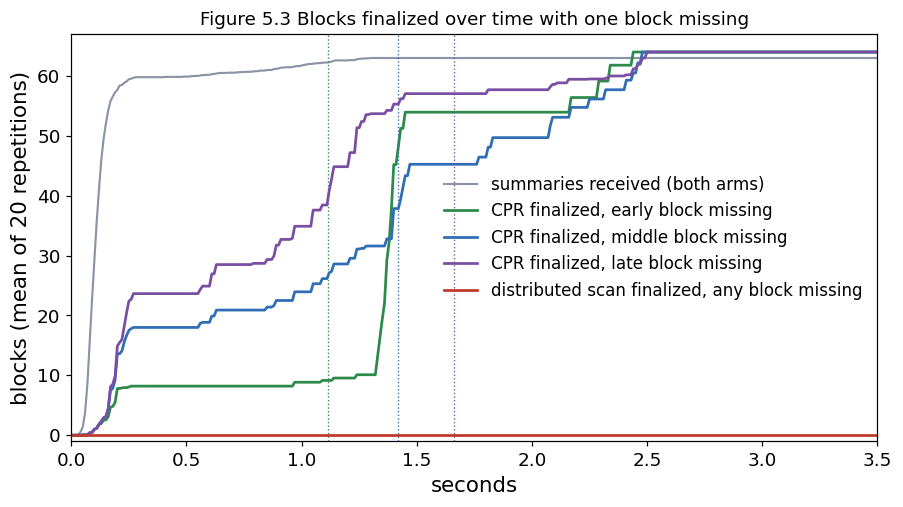

In [4]:
t = m["t"]
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.plot(t, m["curves"]["early"]["received"], color=MUTED, lw=1.4,
        label="summaries received (both arms)")
for region, colour in REGION_COLOURS.items():
    c = m["curves"][region]
    ax.plot(t, c["cpr_finalized"], color=colour, lw=1.8,
            label=f"CPR finalized, {region} block missing")
    ax.axvline(c["declared"], color=colour, lw=0.9, ls=":")
ax.plot(t, np.zeros_like(t), color=DISTRIBUTED, lw=1.8,
        label="distributed scan finalized, any block missing")
ax.set_xlabel("seconds")
ax.set_ylabel(f"blocks (mean of {ex.REPETITIONS} repetitions)")
ax.set_xlim(0, 3.5)
ax.set_ylim(-1, ex.N_BLOCKS + 3)
ax.legend(frameon=False, loc="center right")
ax.set_title("Figure 5.3 Blocks finalized over time with one block missing", fontsize=12)
fig.tight_layout()
plt.show()

## 5.2.3 Table 5.4

The participant sweep: 16 to 128 participants, 2,000 epochs per condition, the
input fixed for each count and the arrivals new every epoch. CPR runs each epoch
until its prefix is finalized. The single permanently missing or late participant
is the last one in the sequence.

In [5]:
p = ex.participants()
cell = {(r["participants"], r["scenario"]): r for r in p}
sizes = (16, 32, 64, 128)
table("Table 5.4 Distributed-scan completion rate and CPR 95th-percentile completion time",
      (("participants", 13), ("dist. 2%", 10), ("dist. 5%", 10), ("CPR p95 2% (s)", 16),
       ("CPR p95 5% (s)", 16)),
      [(n, fmt(cell[n, '2%']['distributed_completion'], 1, 100) + '%',
        fmt(cell[n, '5%']['distributed_completion'], 1, 100) + '%',
        fmt(cell[n, '2%']['cpr_p95']), fmt(cell[n, '5%']['cpr_p95'])) for n in sizes])
print("\nCPR completed every epoch:", all(r["cpr_completion"] == 1.0 for r in p))
missing = [cell[n, "one missing"] for n in sizes]
late = [cell[n, "one 3 s late"] for n in sizes]
print("one participant permanently missing: distributed completion "
      + ", ".join(f"{r['distributed_completion']:.0%}" for r in missing)
      + "; CPR p95 " + ", ".join(f"{r['cpr_p95']:.2f}" for r in missing) + " s")
print("one participant 3 s late           : distributed p95 "
      + ", ".join(f"{r['distributed_p95']:.2f}" for r in late)
      + " s; CPR p95 " + ", ".join(f"{r['cpr_p95']:.2f}" for r in late) + " s")

Table 5.4 Distributed-scan completion rate and CPR 95th-percentile completion time
   participants  dist. 2%  dist. 5%  CPR p95 2% (s)  CPR p95 5% (s)
             16     72.4%     43.6%            1.45            2.65
             32     50.5%     17.7%            2.59            4.92
             64     27.5%      3.9%            3.86            7.43
            128      7.2%      0.3%            7.26           13.30

CPR completed every epoch: True
one participant permanently missing: distributed completion 0%, 0%, 0%, 0%; CPR p95 1.46, 1.48, 1.50, 1.52 s
one participant 3 s late           : distributed p95 3.18, 3.18, 3.18, 3.18 s; CPR p95 1.46, 1.48, 1.50, 1.52 s


## 5.5 Table 5.5

The repair deadline, against an early block whose worker is slow, not dead, and
reports 2 seconds late. 20 repetitions per setting.

In [6]:
rd = ex.repair_deadline()
table("Table 5.5 Repair deadline against T100 and repairs",
      (("repair deadline (s)", 21), ("T100 (s)", 10), ("repairs per run", 17)),
      [(fmt(r['repair_deadline']), fmt(r['t100']), fmt(r['repairs']))
       for r in rd["rows"]])
print("\nevery run bitwise equal to listing 5.5:", rd["bitwise_equal_to_listing_5_5"])

Table 5.5 Repair deadline against T100 and repairs
    repair deadline (s)  T100 (s)  repairs per run
                   0.15      1.09             1.90
                   0.30      1.17             1.40
                   0.75      1.54             1.10
                   1.50      2.09             0.75
                   3.00      2.10             0.00

every run bitwise equal to listing 5.5: True


## 5.5 Table 5.6

The lookahead window, with one early block permanently missing. Max pending is the
largest number of accepted summaries waiting beyond the frontier at any point in a
run.

In [7]:
la = ex.lookahead()
table("Table 5.6 Lookahead window against T100 and pending state",
      (("lookahead W", 13), ("T100 (s)", 10), ("max pending", 13)),
      [(r["lookahead"], fmt(r['t100']), fmt(r['max_pending'], 1)) for r in la["rows"]])
print("\nevery run bitwise equal to listing 5.5:", la["bitwise_equal_to_listing_5_5"])

Table 5.6 Lookahead window against T100 and pending state
    lookahead W  T100 (s)  max pending
              2      2.36          1.0
              4      1.98          3.0
              8      1.76          7.0
             16      1.65         15.0
             64      1.52         55.6

every run bitwise equal to listing 5.5: True


## 5.5 Table 5.7

The checkpoint interval. The coordinator restarts once per run at 1.6 seconds and
recovers with listing 5.12. The checkpoint and log are held in memory, so this
counts replay work; it does not measure storage cost or restart latency.

In [8]:
ck = ex.checkpoint_interval()
table("Table 5.7 Checkpoint interval against replay work",
      (("checkpoint interval (blocks)", 30), ("replayed records", 18), ("blocks refinalized", 20)),
      [(r["interval"], fmt(r['replayed'], 1), fmt(r['refinalized'], 1)) for r in ck["rows"]])
print("\nT100 at every interval:", sorted({round(r["t100"], 2) for r in ck["rows"]}), "s")
print("every refinalized block given the same carry:", ck["refinalized_with_the_same_carry"])
print("every run bitwise equal to listing 5.5:", ck["bitwise_equal_to_listing_5_5"])

Table 5.7 Checkpoint interval against replay work
    checkpoint interval (blocks)  replayed records  blocks refinalized
                               4              16.3                 1.7
                               8              18.1                 3.5
                              16              22.5                 7.9
                              32              31.3                16.7
                              64              34.5                19.9

T100 at every interval: [3.36] s
every refinalized block given the same carry: True
every run bitwise equal to listing 5.5: True


## What the harness does not show

**The network.** Workers are seeded finish times, not machines, and a replacement
worker is a fixed 0.45-second delay. Nothing crosses a network. That is what
`simulated_decentralized` means.

**Wall-clock coordination.** `cpr_scan.py` runs listing 5.11 for real, with threads
as workers, one worker that fails, and a spare GPU that repairs its block:
`python cpr_scan.py`. Listing 5.5 runs the same way from `distributed_scan.py`, and
listing 5.6 runs under MPI: `mpiexec -n 4 python collective_scan.py`.

**Durable recovery.** The checkpoint and summary log live in memory. Table 5.7
counts what a restart replays; it does not measure writing them to storage or
restarting a real process.